# Caso 2 · Renovaciones en Capesa — Diagnóstico

5 gestores hacen ~50 llamadas diarias cada uno. El estándar es contactar al cliente **20 días antes** del vencimiento, pero desde diciembre de 2025 el 57 % de los primeros contactos ocurre **3 días antes o menos** (46 % en los 13 meses, 10 % con 7 gestores). Este notebook mide el problema, sus causas y su costo; la solución está en [`02_prototipo_priorizacion`](02_prototipo_priorizacion.ipynb). Parte de la base limpia de [`00_limpieza`](00_limpieza.ipynb).

| Dato | Valor |
|---|---|
| Periodo | Vencimientos sep-2025 → sep-2026 (13 meses) |
| Dotación | 7 gestores hasta nov-2025; 5 desde dic-2025 |
| Meta | 50 llamadas/día por gestor; 70 % de renovación |

## 1. Supuestos
Decisiones que condicionan los resultados de este notebook y por qué se tomaron. En el texto y en el código se citan por su código.

| Código | Supuesto | Por qué | Dónde se aplica |
|---|---|---|---|
| **S2.5** | Las 222 pólizas renovadas sin llamada de *Cierre* conservan su resultado. Como todas tienen teléfono inválido, el prototipo (`02`) las saca de la cola telefónica (corrección de datos); en las curvas del diagnóstico (`01`) se mantienen. | *Renovó* es el dato oficial, pero ninguna tuvo un contacto efectivo y todas tienen teléfono inválido: su renovación no se puede atribuir a la gestión telefónica. Excluirlas del diagnóstico movería la tasa del tramo 8–14 en 0.3 puntos y la pérdida estratificada en menos de USD 100 al mes. | §2 |
| **S2.8** | **Anticipación** = días entre el primer **intento** de contacto y el vencimiento. | Así define el diccionario *Fecha primer contacto*. La anticipación al primer contacto atendido (`lead_days_effective`) queda disponible para sensibilidad. | §4 |
| **S2.9** | **Comisión potencial** = prima de renovación × % comisión; comisión ganada = potencial × renovó. | Es lo que Capesa cobra si la póliza renueva: mide el valor de cada póliza y el costo de perderla. | §3.2 |
| **S2.10** | Días hábiles de lunes a viernes, sin feriados (`pd.bdate_range`). | Es el horario de la hoja *Equipo*. La bitácora registra llamadas en feriados, así que no se descuentan; el efecto es ~3.5 % de capacidad. | §7 |
| **S2.11** | Capacidad = 50 llamadas por gestor y día hábil; con 5 gestores, 250 al día (`daily_call_target`, `AGENTES`). | Es la meta de la hoja *Equipo* y los gestores la cumplen desde diciembre (~52 llamadas al día). | §7 |

In [1]:
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve().parents[1]  # el notebook corre desde notebooks/caso2/
PROCESSED = ROOT / "data" / "processed" / "caso2_limpio.pkl"
assert PROCESSED.is_file(), f"No existe {PROCESSED}: ejecuta primero 00_limpieza.ipynb"
d = SimpleNamespace(**pd.read_pickle(PROCESSED))  # base limpia escrita por 00_limpieza.ipynb
STAFFING_CHANGE_DATE = d.params["staffing_change_date"]
DAILY_CALL_TARGET = d.params["daily_call_target"]
STANDARD_LEAD_DAYS = d.params["standard_lead_days"]
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update(
    {
        "figure.figsize": (11, 4.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
    }
)
ren, log = d.renewals, d.calls
PERIODO_5 = ren["active_agents"] == 5


def business_days_per_month(start, end):
    return pd.Series(pd.bdate_range(start, end)).dt.to_period("M").value_counts().sort_index()


pd.Series(
    {k: len(v) for k, v in vars(d).items() if isinstance(v, pd.DataFrame)}, name="filas en la base limpia"
).to_frame()

,filas en la base limpia
renewals,25200
calls,78058
team,7
staffing,2
quality,9


In [2]:
# La hoja Equipo trae dos tablas apiladas: los gestores y, más abajo, la dotación por periodo
display(
    d.team[
        [
            "Código",
            "Nombre",
            "Fecha de ingreso al área",
            "Fecha de salida",
            "Estado",
            "Meta llamadas diarias",
            "Meta tasa de renovación",
        ]
    ]
)
display(d.staffing)

,Código,Nombre,Fecha de ingreso al área,Fecha de salida,Estado,Meta llamadas diarias,Meta tasa de renovación
0,G01,Ernesto Ramón Altamirano,2019-03-04 00:00:00,NaN,Activo,50.00,0.70
1,G02,Luis Fernando Gaitán,2021-08-16 00:00:00,NaN,Activo,50.00,0.70
2,G03,Karla Vanessa Úbeda,2017-01-09 00:00:00,NaN,Activo,50.00,0.70
3,G04,Martha Elena Zeledón,2022-05-02 00:00:00,NaN,Activo,50.00,0.70
4,G05,Ana Lucía Morales,2023-11-06 00:00:00,NaN,Activo,50.00,0.70
5,G06,Roberto Carlos Membreño,2020-02-10 00:00:00,2025-11-30 00:00:00,Retirado,50.00,0.70
6,G07,Silvia Patricia Obando,2022-09-19 00:00:00,2025-11-30 00:00:00,Retirado,50.00,0.70


,Periodo,Gestores,Códigos,Comentario
11,01/09/2025 - 30/11/2025,7,G01 a G07,Trimestre con dotación completa
12,01/12/2025 - a la fecha,5,G01 a G05,Salida de G06 y G07; carteras redistribuidas


## 2. Calidad de datos
Detalle en `00_limpieza`. La bitácora cuadra con la hoja Renovaciones y **522 pólizas no son contactables por teléfono** (formato inválido o número de relleno). Las 222 pólizas renovadas sin llamada de cierre tienen todas teléfono inválido.

*Supuesto S2.5 (ver §1).*

In [3]:
d.quality.style.hide(axis="index")

Hoja,Problema,Filas,Tratamiento
Renovaciones,Filas duplicadas exactas,151,Eliminadas (S2.1)
Renovaciones,'Renovó' con 4 grafías (Sí/SI/No/no),126,Normalizado a 1/0 (S2.2)
Renovaciones,"Teléfono nulo, de relleno o con formato inválido",357,Marcado como no contactable (S2.3)
Renovaciones,Teléfono con formato válido compartido por decenas de clientes,165,Marcado como no contactable (S2.3)
Renovaciones,Fecha de primer contacto nula,151,Completada con la primera llamada de la bitácora (S2.4)
Renovaciones,Renovó = Sí sin llamada de 'Cierre' ni contacto efectivo,222,Se respeta 'Renovó'; se mantiene en el diagnóstico y el prototipo la saca de la cola (S2.5)
Renovaciones,Primer contacto después del vencimiento,579,Se mantiene: contacto tardío real (S2.6)
Bitácora,"IDs duplicados, pólizas inexistentes, llamadas fuera de horario",0,Sin tratamiento
Ambas,Intentos y primer contacto vs bitácora,0 dif.,Cuadra: sin tratamiento


## 3. Volumen y cartera

### 3.1 Vencimientos por mes

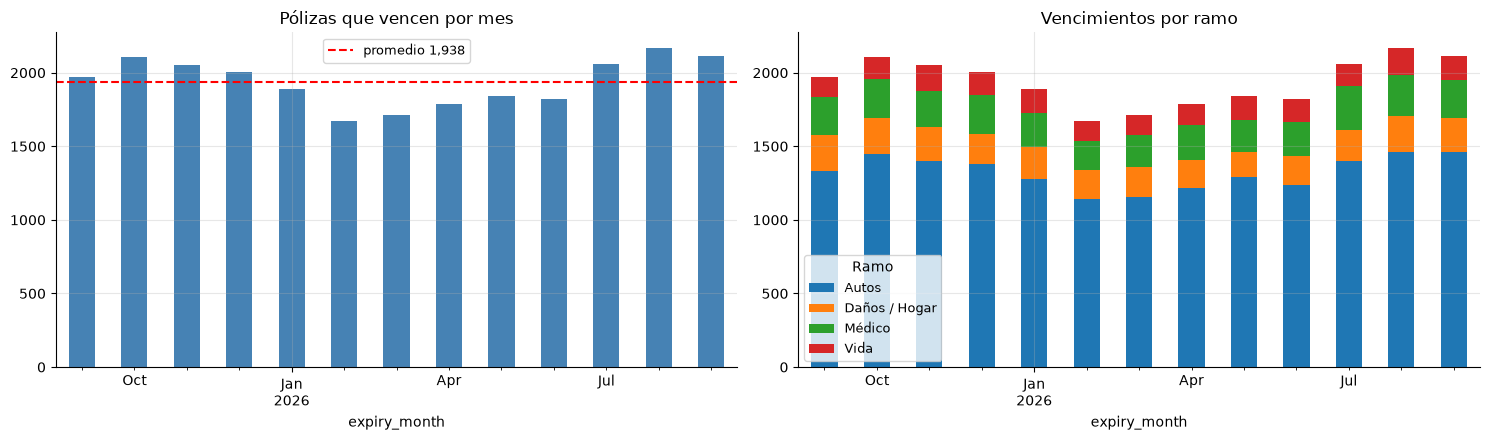

In [4]:
venc = ren.groupby("expiry_month").size()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
venc.plot(kind="bar", ax=axes[0], color="steelblue", title="Pólizas que vencen por mes")
axes[0].axhline(venc.mean(), color="r", ls="--", label=f"promedio {venc.mean():,.0f}")
axes[0].legend()
ren.groupby(["expiry_month", "Ramo"]).size().unstack().plot(
    kind="bar", stacked=True, ax=axes[1], title="Vencimientos por ramo"
)
plt.tight_layout()
plt.show()

Vencen **~2,000 pólizas al mes** con una mezcla de ramos estable. La carga no cambió en diciembre; cambió el número de gestores.

### 3.2 Valor de la cartera por segmento

*Supuesto S2.9 (ver §1).*

In [5]:
def resumen(col):
    t = ren.groupby(col).agg(
        polizas=("Póliza", "size"),
        tasa_renovacion=("renewed", "mean"),
        prima_mediana=("Prima de renovación (USD)", "median"),
        comision_media=("potential_commission", "mean"),
        comision_total=("potential_commission", "sum"),
    )
    t["% comisión de cartera"] = t["comision_total"] / t["comision_total"].sum()
    return t.sort_values("comision_total", ascending=False)


fmt = {
    "tasa_renovacion": "{:.1%}",
    "% comisión de cartera": "{:.1%}",
    "prima_mediana": "{:,.0f}",
    "comision_media": "{:,.0f}",
    "comision_total": "{:,.0f}",
}
for c in ["Ramo", "Segmento", "Forma de pago", "Origen"]:
    display(Markdown(f"**Por {c.lower()}**"))
    display(resumen(c).style.format(fmt))

**Por ramo**

,polizas,tasa_renovacion,prima_mediana,comision_media,comision_total,% comisión de cartera
Ramo,,,,,,
Autos,17206,54.6%,687,184,"3,174,475",69.6%
Médico,3188,55.2%,"1,993",236,"752,269",16.5%
Vida,2014,55.6%,789,186,"374,458",8.2%
Daños / Hogar,2792,42.4%,466,94,"262,082",5.7%


**Por segmento**

,polizas,tasa_renovacion,prima_mediana,comision_media,comision_total,% comisión de cartera
Segmento,,,,,,
Individual,18087,50.7%,604,111,"2,005,831",44.0%
Flota corporativa,1530,87.5%,"7,956",907,"1,388,166",30.4%
Pyme,5583,52.7%,"1,142",209,"1,169,288",25.6%


**Por forma de pago**

,polizas,tasa_renovacion,prima_mediana,comision_media,comision_total,% comisión de cartera
Forma de pago,,,,,,
Manual,20571,44.5%,734,190,"3,911,864",85.7%
Domiciliado,2373,94.6%,903,166,"393,366",8.6%
Financiado,2256,91.1%,650,114,"258,054",5.7%


**Por origen**

,polizas,tasa_renovacion,prima_mediana,comision_media,comision_total,% comisión de cartera
Origen,,,,,,
Otro canal,16186,49.4%,770,173,"2,797,408",61.3%
Venta de vehículo Casa Pellas,9014,60.6%,696,196,"1,765,876",38.7%


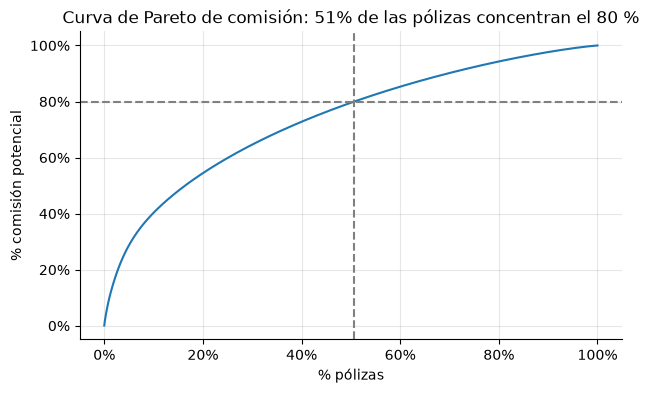

In [6]:
# Concentración del valor: ¿qué % de pólizas genera el 80 % de la comisión?
s = ren["potential_commission"].sort_values(ascending=False)
cum = s.cumsum() / s.sum()
p80 = (cum <= 0.8).mean()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(s) + 1) / len(s), cum.values)
ax.axhline(0.8, ls="--", color="gray")
ax.axvline(p80, ls="--", color="gray")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title(f"Curva de Pareto de comisión: {p80:.0%} de las pólizas concentran el 80 %")
ax.set_xlabel("% pólizas")
ax.set_ylabel("% comisión potencial")
plt.show()

- **Autos** es dos tercios de las pólizas, pero Médico y Flota corporativa tienen comisiones medias mucho mayores.
- **Flota corporativa** es el 6 % de las pólizas, el 30 % de la comisión y renueva al 88 %.
- **Domiciliadas y financiadas** renuevan muy por encima del pago manual.
- **El valor está concentrado:** la mitad de las pólizas genera el 80 % de la comisión.

## 4. Anticipación del primer contacto: el problema

*Supuesto S2.8 (ver §1).*

Mediana de anticipación: 4 días | % con ≤ 3 días: 46.0% | % con ≥ 20 días (estándar): 15.5%


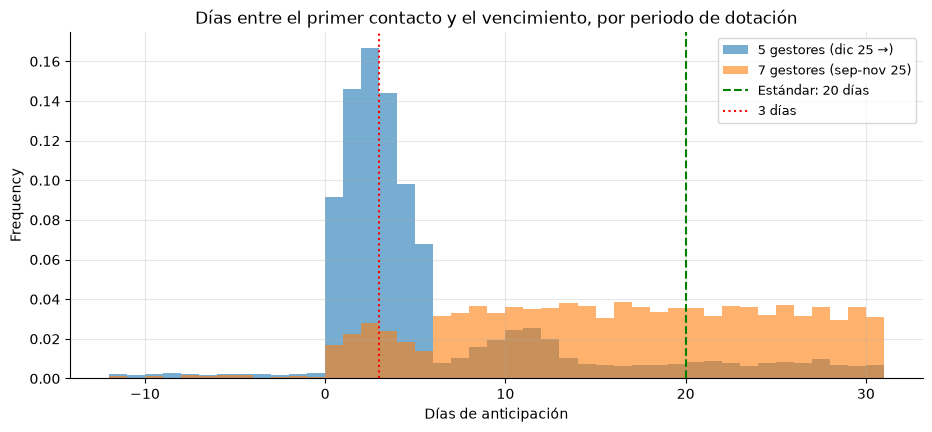

In [7]:
print(
    f"Mediana de anticipación: {ren['lead_days'].median():.0f} días | % con ≤ 3 días: {(ren['lead_days'] <= 3).mean():.1%} "
    f"| % con ≥ {STANDARD_LEAD_DAYS} días (estándar): {(ren['lead_days'] >= STANDARD_LEAD_DAYS).mean():.1%}"
)
fig, ax = plt.subplots()
for per, g_ in ren.groupby("period"):
    g_["lead_days"].plot(kind="hist", bins=range(-12, 32), alpha=0.6, density=True, ax=ax, label=per)
ax.axvline(STANDARD_LEAD_DAYS, color="g", ls="--", label=f"Estándar: {STANDARD_LEAD_DAYS} días")
ax.axvline(3, color="r", ls=":", label="3 días")
ax.set_title("Días entre el primer contacto y el vencimiento, por periodo de dotación")
ax.set_xlabel("Días de anticipación")
ax.legend()
plt.show()

,polizas,anticipacion_mediana,pct_le3,pct_ge20,tasa_renovacion,comision_real,gestores
expiry_month,,,,,,,
2025-09,1971,16.000000,10%,37%,61.6%,"234,840",7
2025-10,2108,16.000000,11%,38%,62.0%,"253,033",7
2025-11,2050,16.000000,11%,37%,62.4%,"260,141",7
2025-12,2005,3.000000,56%,10%,51.2%,"232,057",5
2026-01,1888,3.000000,57%,10%,51.5%,"215,658",5
2026-02,1669,3.000000,56%,10%,51.5%,"185,770",5
2026-03,1712,3.000000,55%,9%,49.9%,"178,953",5
2026-04,1790,3.000000,57%,10%,51.3%,"201,249",5
2026-05,1841,3.000000,58%,8%,49.3%,"215,429",5


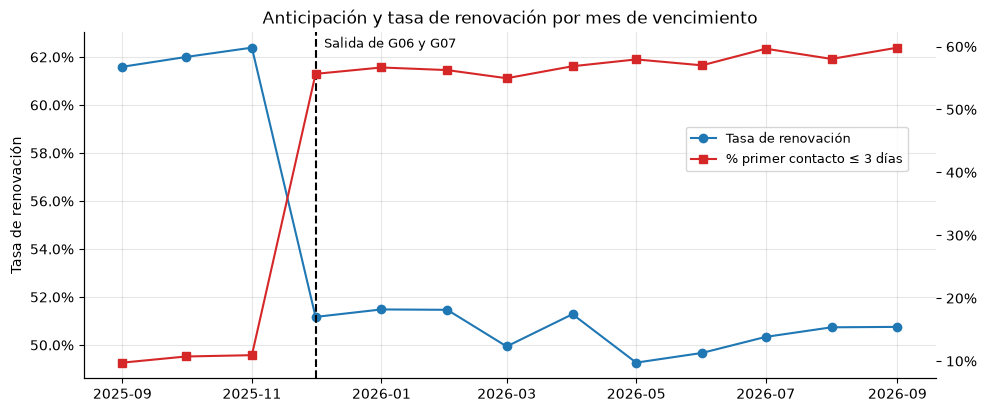

In [8]:
m = ren.groupby("expiry_month").agg(
    polizas=("Póliza", "size"),
    anticipacion_mediana=("lead_days", "median"),
    pct_le3=("lead_days", lambda s: (s <= 3).mean()),
    pct_ge20=("lead_days", lambda s: (s >= STANDARD_LEAD_DAYS).mean()),
    tasa_renovacion=("renewed", "mean"),
    comision_real=("earned_commission", "sum"),
    gestores=("active_agents", "first"),
)
display(
    m.style.format(
        {"pct_le3": "{:.0%}", "pct_ge20": "{:.0%}", "tasa_renovacion": "{:.1%}", "comision_real": "{:,.0f}"}
    )
)

fig, ax1 = plt.subplots()
ax1.plot(
    m.index.to_timestamp(), m["tasa_renovacion"], marker="o", color="tab:blue", label="Tasa de renovación"
)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax1.set_ylabel("Tasa de renovación")
ax2 = ax1.twinx()
ax2.plot(
    m.index.to_timestamp(), m["pct_le3"], marker="s", color="tab:red", label="% primer contacto ≤ 3 días"
)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax2.grid(False)
ax1.axvline(STAFFING_CHANGE_DATE, color="k", ls="--")
ax1.text(
    STAFFING_CHANGE_DATE + pd.Timedelta(days=4), m["tasa_renovacion"].max(), "Salida de G06 y G07", fontsize=9
)
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.62))
ax1.set_title("Anticipación y tasa de renovación por mes de vencimiento")
plt.show()

In [9]:
# ¿Es un escalón por falta de capacidad (cola que se acumula) o un cambio en cuándo se abre cada expediente?
# Tres vistas desde la bitácora.
# 1) ¿Cuándo se abre cada expediente? Fracción de pólizas cuya primera llamada ocurrió antes del mes en que vencen
mes_primera = ren["first_call"].dt.to_period("M")
apertura_previa = (mes_primera < ren["expiry_month"]).groupby(ren["expiry_month"]).mean()
print("1) Pólizas abiertas (primera llamada) antes del mes de su vencimiento:")
print("   " + "  ".join(f"{k}: {v:.0%}" for k, v in apertura_previa.loc["2025-10":"2026-02"].items()))

# 2) Caudal de llamadas por mes calendario (agosto de 2025 y octubre de 2026 son parciales; noviembre de 2025 es el mes de transición)
mes = log.groupby("month").size()
ultimo_mes_completo = ren["expiry_month"].max()
dias_habiles = business_days_per_month(mes.index.min().start_time, mes.index.max().end_time)
caudal = pd.DataFrame(
    {
        "llamadas": mes,
        "por día hábil": mes / dias_habiles.reindex(mes.index),
        "gestores activos": log.groupby("month")["Gestor"].nunique(),
    }
)
caudal["por gestor y día"] = caudal["por día hábil"] / caudal["gestores activos"]
print("\n2) Llamadas por mes (agosto de 2025 y octubre de 2026 son parciales):")
print(caudal.round(1).to_string())
regimen7 = caudal.loc["2025-09":"2025-10"]
regimen5 = caudal.loc[str(STAFFING_CHANGE_DATE.to_period("M")) : str(ultimo_mes_completo)]
caida_caudal = 1 - regimen5["por día hábil"].mean() / regimen7["por día hábil"].mean()
caida_mes = regimen7["llamadas"].mean() - regimen5["llamadas"].mean()
gestor_dia = (
    log[log["month"].between(STAFFING_CHANGE_DATE.to_period("M"), ultimo_mes_completo)]
    .groupby(["Gestor", "date"])
    .size()
)
print(
    f"   Con 7 gestores en régimen (sep-oct): {regimen7['por día hábil'].mean():.0f} llamadas por día hábil ({regimen7['por gestor y día'].mean():.0f} por gestor); "
    f"con 5: {regimen5['por día hábil'].mean():.0f} ({regimen5['por gestor y día'].mean():.0f} por gestor). "
    f"El caudal del equipo cayó {caida_caudal:.0%} (~{caida_mes:,.0f} llamadas al mes); desde diciembre el {(gestor_dia > DAILY_CALL_TARGET).mean():.0%} de los gestor-día supera las {DAILY_CALL_TARGET} llamadas (p95 = {gestor_dia.quantile(0.95):.0f})."
)
nov = log[log["month"] == "2025-11"]
cap_nov = 7 * DAILY_CALL_TARGET * business_days_per_month("2025-11-01", "2025-11-30").iloc[0]
print(
    f"   Noviembre de 2025, aún con 7 gestores: {len(nov):,} llamadas = {len(nov) / cap_nov:.0%} de su capacidad teórica, "
    f"y solo el {apertura_previa.loc['2025-12']:.0%} de los expedientes de diciembre se abrió en noviembre."
)

r5 = ren[PERIODO_5]
por_dia_mes = r5.groupby(r5["Fecha de vencimiento"].dt.day)["lead_days"].median()
print(
    f"\n3) Con 5 gestores, anticipación mediana según el día del mes en que vence la póliza: "
    f"mínimo {por_dia_mes.min():.0f}, máximo {por_dia_mes.max():.0f} (una cola que se acumula haría caer la anticipación a lo largo del mes)."
)

1) Pólizas abiertas (primera llamada) antes del mes de su vencimiento:
   2025-10: 52%  2025-11: 58%  2025-12: 16%  2026-01: 19%  2026-02: 21%

2) Llamadas por mes (agosto de 2025 y octubre de 2026 son parciales):
         llamadas  por día hábil  gestores activos  por gestor y día
month                                                               
2025-08      2444         116.40                 7             16.60
2025-09      6744         306.50                 7             43.80
2025-10      7284         316.70                 7             45.20
2025-11      4247         212.40                 7             30.30
2025-12      6152         267.50                 5             53.50
2026-01      5666         257.50                 5             51.50
2026-02      5036         251.80                 5             50.40
2026-03      5350         243.20                 5             48.60
2026-04      5427         246.70                 5             49.30
2026-05      5229         2

Con 7 gestores la anticipación mediana era **16 días**; desde **diciembre de 2025** (salida de G06 y G07) es **2–3 días**, y la renovación cae. Hay dos causas:

1. **Menos caudal:** de ~310 a ~260 llamadas por día hábil (−16 %). Los 5 gestores ya superan la meta de 50.
2. **Cambió cuándo se abre la cola:** en noviembre, aún con 7 gestores, solo se abrió temprano el 16 % de los expedientes de diciembre (frente al 58 % el mes anterior). Desde entonces la anticipación es de 3 días sin importar el día del mes: es una regla, no un atraso.

La regla de apertura, y por qué cambió, es el primer dato a pedir al área.

## 5. ¿Cuánto importa la anticipación?

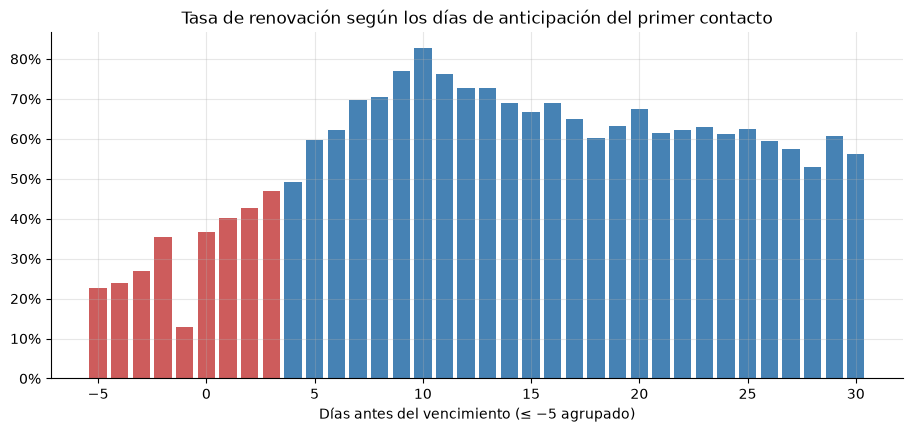

,polizas,tasa_renovacion,% pólizas
lead_bucket,,,
Después del venc.,579,23.0%,2.3%
0-3,11006,42.1%,43.7%
4-7,4109,55.8%,16.3%
8-14,3876,75.1%,15.4%
15-20,2100,65.3%,8.3%
21-25,1798,62.1%,7.1%
26-30,1732,57.4%,6.9%


In [10]:
curva = ren.groupby(ren["lead_days"].clip(-5, 30))["renewed"].agg(["mean", "size"])
fig, ax = plt.subplots()
ax.bar(curva.index, curva["mean"], color=np.where(curva.index <= 3, "indianred", "steelblue"))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Tasa de renovación según los días de anticipación del primer contacto")
ax.set_xlabel("Días antes del vencimiento (≤ −5 agrupado)")
plt.show()

t = ren.groupby("lead_bucket", observed=True).agg(
    polizas=("Póliza", "size"), tasa_renovacion=("renewed", "mean")
)
t["% pólizas"] = t["polizas"] / t["polizas"].sum()
t.style.format({"tasa_renovacion": "{:.1%}", "% pólizas": "{:.1%}"})

In [11]:
# ¿Se sostiene dentro de cada ramo y en cada periodo de dotación? (controla la mezcla de cartera)
display(Markdown("**Tasa de renovación por tramo de anticipación y ramo**"))
display(
    ren.pivot_table(index="lead_bucket", columns="Ramo", values="renewed", aggfunc="mean", observed=True)
    .style.format("{:.0%}")
    .background_gradient(cmap="RdYlGn", axis=None)
)
display(Markdown("**… y por periodo de dotación**"))
display(
    ren.pivot_table(index="lead_bucket", columns="period", values="renewed", aggfunc="mean", observed=True)
    .style.format("{:.0%}")
    .background_gradient(cmap="RdYlGn", axis=None)
)

**Tasa de renovación por tramo de anticipación y ramo**

Ramo,Autos,Daños / Hogar,Médico,Vida
lead_bucket,,,,
Después del venc.,25%,9%,27%,20%
0-3,44%,28%,43%,45%
4-7,57%,46%,57%,59%
8-14,76%,67%,80%,74%
15-20,65%,59%,71%,70%
21-25,64%,48%,61%,71%
26-30,58%,50%,60%,57%


**… y por periodo de dotación**

period,5 gestores (dic 25 →),7 gestores (sep-nov 25)
lead_bucket,,
Después del venc.,21%,33%
0-3,42%,42%
4-7,55%,63%
8-14,76%,73%
15-20,66%,65%
21-25,63%,61%
26-30,60%,56%


- La renovación es máxima con primer contacto **8–14 días** antes (75 %), cae a 42 % en el tramo 0–3 días (41 % sumando los contactos después del vencimiento) y a 60 % con más de 20.
- El patrón se repite en todos los ramos y en los dos periodos.
- La meta no es llamar lo antes posible, sino **llegar a la ventana de 8–14 días**.

In [12]:
mot = pd.crosstab(
    ren.loc[ren["renewed"] == 0, "Motivo de no renovación"],
    ren.loc[ren["renewed"] == 0, "lead_bucket"],
    normalize="columns",
)
mot.style.format("{:.0%}").background_gradient(cmap="Reds", axis=1)

lead_bucket,Después del venc.,0-3,4-7,8-14,15-20,21-25,26-30
Motivo de no renovación,,,,,,,
Canceló el financiamiento / ya no lo exige el banco,0%,1%,1%,1%,1%,1%,0%
Cliente pospuso la decisión,0%,0%,2%,6%,17%,19%,17%
Cotización vencida,0%,0%,0%,0%,15%,15%,17%
Inconformidad con servicio o siniestro,0%,5%,7%,12%,1%,1%,1%
Lo contactó otro corredor más cerca de la fecha,0%,0%,0%,3%,12%,16%,14%
No recordaba el contacto previo,0%,0%,0%,0%,12%,10%,12%
No se logró contactar antes del vencimiento,34%,11%,9%,4%,2%,2%,2%
Otro,3%,7%,8%,13%,8%,8%,7%
Precio / aumento de prima,16%,23%,27%,35%,23%,21%,22%


### 5.1 Otros factores

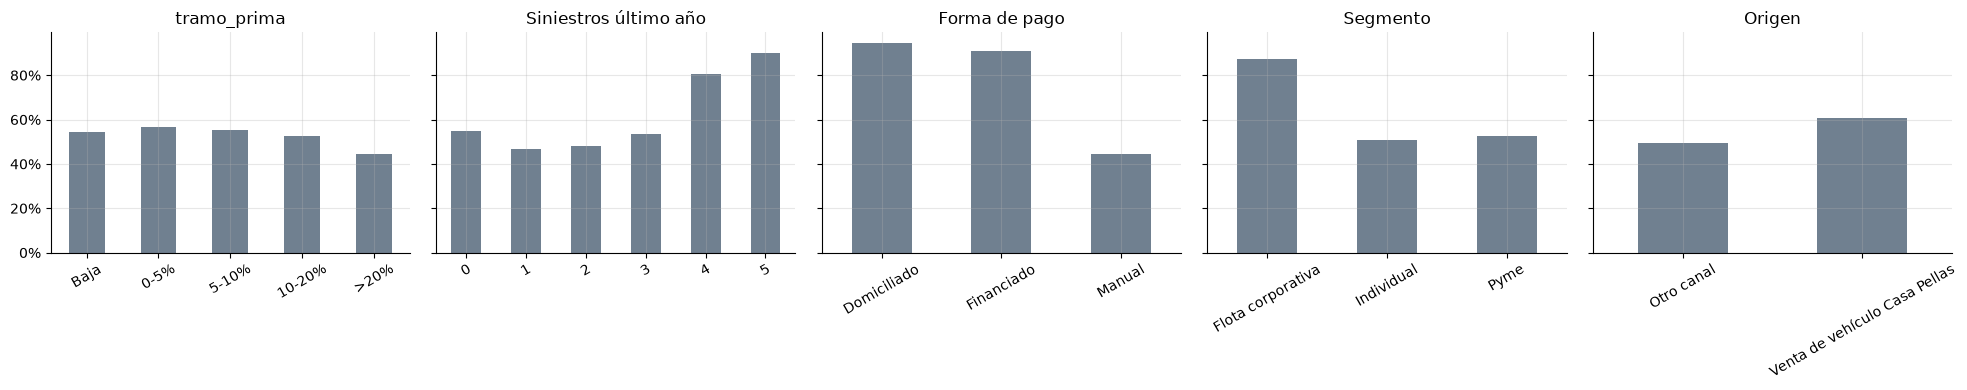

,tasa de renovación,pólizas
Antigüedad del cliente (años),,
"(-1, 0]",53.6%,521
"(0, 2]",51.9%,6938
"(2, 5]",53.2%,9871
"(5, 10]",55.1%,6456
"(10, 30]",54.2%,1414


**Tasa de renovación por tramo de anticipación, forma de pago y segmento**

,Domiciliado / Financiado,Manual · Flota corporativa,Manual · Individual y Pyme
lead_bucket,,,
Después del venc.,94%,82%,4%
0-3,93%,89%,26%
4-7,92%,85%,44%
8-14,93%,88%,70%
15-20,93%,83%,57%
21-25,91%,90%,52%
26-30,94%,89%,47%


,% pólizas,% comisión potencial,Tasa de renovación
Domiciliado / Financiado,18%,14%,93%
Manual · Flota corporativa,6%,30%,88%
Manual · Individual y Pyme,76%,55%,41%


In [13]:
ren["tramo_prima"] = pd.cut(
    ren["% cambio de prima"], [-1, 0, 0.05, 0.10, 0.20, 1], labels=["Baja", "0-5%", "5-10%", "10-20%", ">20%"]
)
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, c in zip(
    axes, ["tramo_prima", "Siniestros último año", "Forma de pago", "Segmento", "Origen"], strict=False
):
    ren.groupby(c, observed=True)["renewed"].mean().plot(kind="bar", ax=ax, color="slategray", title=c)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
antig = ren.groupby(pd.cut(ren["Antigüedad del cliente (años)"], [-1, 0, 2, 5, 10, 30]), observed=True)[
    "renewed"
].agg(["mean", "size"])
display(
    antig.rename(columns={"mean": "tasa de renovación", "size": "pólizas"}).style.format(
        {"tasa de renovación": "{:.1%}"}
    )
)

# ¿Para quién importa la anticipación? Tasa por tramo según forma de pago y segmento
display(Markdown("**Tasa de renovación por tramo de anticipación, forma de pago y segmento**"))
grupo = np.where(
    ren["Forma de pago"] != "Manual",
    "Domiciliado / Financiado",
    np.where(
        ren["Segmento"] == "Flota corporativa", "Manual · Flota corporativa", "Manual · Individual y Pyme"
    ),
)
t_grupo = ren.pivot_table(index="lead_bucket", columns=grupo, values="renewed", aggfunc="mean", observed=True)
display(t_grupo.style.format("{:.0%}").background_gradient(cmap="RdYlGn", axis=None))
peso = pd.Series(grupo).value_counts(normalize=True)
com = ren.groupby(grupo)["potential_commission"].sum() / ren["potential_commission"].sum()
display(
    pd.DataFrame(
        {
            "% pólizas": peso,
            "% comisión potencial": com,
            "Tasa de renovación": ren.groupby(grupo)["renewed"].mean(),
        }
    ).style.format("{:.0%}")
)

- Además de la anticipación pesan la **forma de pago** (domiciliado 95 %, financiado 91 %, manual 44 %) y el **segmento** (Flota corporativa 88 %).
- En domiciliadas, financiadas y flotas la tasa es plana sin importar cuándo se llame.
- La curva solo existe en **pago manual de individuales y pymes** (76 % de las pólizas): 70 % en ventana frente a 26 % a 3 días o menos.
- Por eso la prioridad debe ser **comisión × mejora esperada**, no solo comisión.

## 6. Bitácora: productividad y contactabilidad

,% de llamadas
Resultado,
No contesta,27.3%
Cotización enviada,26.0%
Cierre,17.0%
Pide llamar después,13.9%
Contactado,13.8%
Número equivocado,2.1%


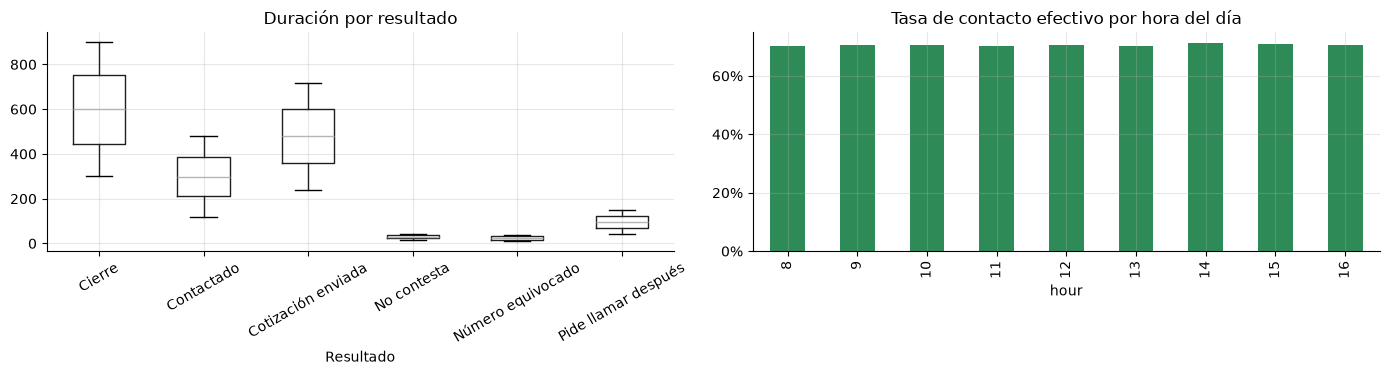

Fecha y hora,Monday,Tuesday,Wednesday,Thursday,Friday
Tasa de contacto efectivo,70.9%,70.3%,70.8%,70.3%,70.6%


In [14]:
display(log["Resultado"].value_counts(normalize=True).to_frame("% de llamadas").style.format("{:.1%}"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
log.boxplot(column="Duración (seg)", by="Resultado", ax=axes[0], rot=30)
axes[0].set_title("Duración por resultado")
fig.suptitle("")
log.groupby("hour")["is_effective"].mean().plot(
    kind="bar", ax=axes[1], color="seagreen", title="Tasa de contacto efectivo por hora del día"
)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.tight_layout()
plt.show()
display(
    log.groupby(log["Fecha y hora"].dt.day_name())["is_effective"]
    .mean()
    .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])
    .to_frame("Tasa de contacto efectivo")
    .T.style.format("{:.1%}")
)

~27 % de las llamadas no se contestan, igual a cualquier hora o día: cambiar el horario no es palanca.

In [15]:
dia = (
    log.groupby(["Gestor", "date"])
    .agg(llamadas=("ID llamada", "size"), seg=("Duración (seg)", "sum"))
    .reset_index()
)
g = dia.groupby("Gestor").agg(
    dias=("date", "nunique"),
    llamadas_dia=("llamadas", "mean"),
    horas_tel_dia=("seg", lambda s: s.mean() / 3600),
)
g = g.join(
    dia[dia["date"] >= STAFFING_CHANGE_DATE]
    .groupby("Gestor")["llamadas"]
    .mean()
    .rename("llamadas_dia_desde_dic")
)
g = g.join(
    ren.groupby("Gestor").agg(
        polizas=("Póliza", "size"),
        tasa_renovacion=("renewed", "mean"),
        anticipacion_mediana=("lead_days", "median"),
        pct_le3=("lead_days", lambda s: (s <= 3).mean()),
        intentos_prom=("Número de intentos", "mean"),
    )
)
g = g.join(d.team.set_index("Código")[["Nombre", "Estado"]])
g.style.format(
    {
        "llamadas_dia": "{:.1f}",
        "llamadas_dia_desde_dic": "{:.1f}",
        "horas_tel_dia": "{:.1f}",
        "tasa_renovacion": "{:.1%}",
        "pct_le3": "{:.0%}",
        "intentos_prom": "{:.2f}",
    }
)

,dias,llamadas_dia,horas_tel_dia,llamadas_dia_desde_dic,polizas,tasa_renovacion,anticipacion_mediana,pct_le3,intentos_prom,Nombre,Estado
Gestor,,,,,,,,,,,
G01,311,45.7,3.6,49.8,4589,50.3%,3.000000,55%,3.10,Ernesto Ramón Altamirano,Activo
G02,311,47.6,3.8,51.9,4746,49.2%,3.000000,54%,3.12,Luis Fernando Gaitán,Activo
G03,311,44.8,3.8,48.6,4687,64.9%,10.000000,23%,2.97,Karla Vanessa Úbeda,Activo
G04,314,47.0,3.8,50.7,4768,51.9%,3.000000,54%,3.09,Martha Elena Zeledón,Activo
G05,319,45.6,3.6,49.9,4660,48.8%,3.000000,57%,3.12,Ana Lucía Morales,Activo
G06,85,35.3,2.6,nan,891,58.7%,16.000000,11%,3.38,Roberto Carlos Membreño,Retirado
G07,84,33.1,2.4,nan,859,58.2%,16.000000,11%,3.25,Silvia Patricia Obando,Retirado


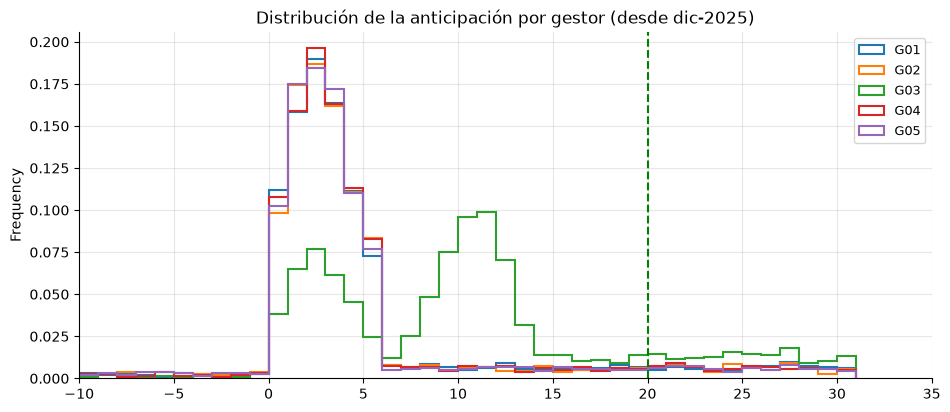

**Cartera por gestor y ramo (desde dic-2025)**

Ramo,Autos,Daños / Hogar,Médico,Vida,All
Gestor,,,,,
G01,2573,389,451,312,3725
G02,2632,408,475,327,3842
G03,2597,431,530,308,3866
G04,2646,405,491,298,3840
G05,2579,436,479,304,3798
All,13027,2069,2426,1549,19071


**Anticipación mediana por cuartil de prima (Q1 = primas más bajas, Q4 = más altas)**

Prima de renovación (USD),Q1,Q2,Q3,Q4
Gestor,,,,
G01,3,2,2,3
G02,3,3,2,3
G03,10,10,10,10
G04,2,3,3,3
G05,3,3,2,2


In [16]:
# Desde dic-2025: ¿todos los gestores llaman igual de tarde? ¿Alguno prioriza por valor de la póliza?
r5 = ren[PERIODO_5]
fig, ax = plt.subplots()
for gst, g_ in r5.groupby("Gestor"):
    g_["lead_days"].plot(
        kind="hist", bins=range(-12, 32), density=True, histtype="step", lw=1.5, ax=ax, label=gst
    )
ax.axvline(STANDARD_LEAD_DAYS, color="g", ls="--")
ax.set_xlim(-10, 35)
ax.set_title("Distribución de la anticipación por gestor (desde dic-2025)")
ax.legend()
plt.show()

display(Markdown("**Cartera por gestor y ramo (desde dic-2025)**"))
display(pd.crosstab(r5["Gestor"], r5["Ramo"], margins=True))
display(Markdown("**Anticipación mediana por cuartil de prima (Q1 = primas más bajas, Q4 = más altas)**"))
display(
    r5.groupby(
        ["Gestor", pd.qcut(r5["Prima de renovación (USD)"], 4, labels=["Q1", "Q2", "Q3", "Q4"])],
        observed=True,
    )["lead_days"]
    .median()
    .unstack()
    .style.format("{:.0f}")
)

In [17]:
# ¿Cuánto de la ventaja de G03 es la anticipación? Estandarización directa: tasas del resto del equipo por
# tramo × forma de pago × segmento, aplicadas a la mezcla de pólizas de G03
g03, resto = r5[r5["Gestor"] == "G03"], r5[r5["Gestor"] != "G03"]
estratos = ["lead_bucket", "Forma de pago", "Segmento"]
mezcla_g03 = g03.groupby(estratos, observed=True).size()
tasas_resto = resto.groupby(estratos, observed=True)["renewed"].mean().reindex(mezcla_g03.index)
esperado_g03 = (tasas_resto.fillna(resto["renewed"].mean()) * mezcla_g03).sum() / len(g03)
ventaja = g03["renewed"].mean() - resto["renewed"].mean()
explicado = (esperado_g03 - resto["renewed"].mean()) / ventaja
print(
    f"Desde dic-2025, G03 renueva {g03['renewed'].mean():.1%} frente a {resto['renewed'].mean():.1%} del resto (+{ventaja * 100:.1f} pts). "
    f"Con las tasas del resto aplicadas a la mezcla de G03 se esperaría {esperado_g03:.1%}: el {explicado:.0%} de la ventaja "
    f"se explica por la mezcla (sobre todo el tramo de anticipación) y quedan {(g03['renewed'].mean() - esperado_g03) * 100:.1f} pts sin explicar."
)
r7 = ren[~PERIODO_5]
print(
    f"Con 7 gestores: G03 {r7.loc[r7['Gestor'] == 'G03', 'renewed'].mean():.1%} frente a {r7.loc[r7['Gestor'] != 'G03', 'renewed'].mean():.1%} del resto, "
    f"con la misma anticipación mediana ({r7.loc[r7['Gestor'] == 'G03', 'lead_days'].median():.0f} frente a {r7.loc[r7['Gestor'] != 'G03', 'lead_days'].median():.0f} días)."
)

Desde dic-2025, G03 renueva 64.7% frente a 47.0% del resto (+17.6 pts). Con las tasas del resto aplicadas a la mezcla de G03 se esperaría 60.2%: el 75% de la ventaja se explica por la mezcla (sobre todo el tramo de anticipación) y quedan 4.5 pts sin explicar.
Con 7 gestores: G03 65.9% frente a 61.4% del resto, con la misma anticipación mediana (16 frente a 16 días).


Los gestores están en la meta (49–52 llamadas al día desde diciembre): no es un problema de esfuerzo.
- **Nadie prioriza por valor:** la anticipación es la misma para primas bajas y altas.
- **G03** mantiene 10 días de anticipación y renueva 65 % frente a ~47 % del resto; ~75 % de esa ventaja se explica por la anticipación misma. Demuestra que con 5 gestores se puede llegar a la ventana.

In [18]:
primer = ren["attempt_first_effective"]
print("Intento en el que se logra el primer contacto efectivo (% de pólizas):")
print(primer.value_counts(normalize=True).sort_index().head(6).round(3).to_string())
print(
    f"Pólizas que nunca lograron contacto efectivo: {primer.isna().mean():.1%} "
    f"(de ellas, con teléfono inválido: {(primer.isna() & ~ren['valid_phone']).sum()})"
)
print(f"Intentos promedio por póliza: {ren['Número de intentos'].mean():.2f}")

display(Markdown("**Tasa de renovación según el resultado de la última llamada**"))
display(
    ren.groupby("last_result")["renewed"]
    .agg(["mean", "size"])
    .rename(columns={"mean": "tasa de renovación", "size": "pólizas"})
    .sort_values("tasa de renovación")
    .style.format({"tasa de renovación": "{:.1%}"})
)

Intento en el que se logra el primer contacto efectivo (% de pólizas):
attempt_first_effective
1.00   0.75
2.00   0.19
3.00   0.05
4.00   0.01
5.00   0.00
6.00   0.00
Pólizas que nunca lograron contacto efectivo: 5.7% (de ellas, con teléfono inválido: 522)
Intentos promedio por póliza: 3.10


**Tasa de renovación según el resultado de la última llamada**

,tasa de renovación,pólizas
last_result,,
Contactado,0.0%,5660
Cotización enviada,0.0%,2303
No contesta,2.2%,3697
Número equivocado,45.0%,309
Cierre,100.0%,13231


- Tres de cada cuatro pólizas contactadas lo logran al primer intento (el 70 % del total), pero se hacen **3.1 llamadas por póliza** por los seguimientos.
- Las 522 pólizas con teléfono inválido consumieron **2,401 llamadas** sin lograr un contacto.
- Ojo con la tabla anterior: *Cierre* es siempre la última llamada de una renovada, así que el 0 % de los demás finales es por construcción. Que una llamada más recupere las 2,303 pólizas en *Cotización enviada* es una hipótesis para el piloto.

## 7. Capacidad vs carga

*Supuestos S2.10, S2.11 (ver §1).*

,vencimientos,llamadas realizadas,días hábiles,intentos por póliza,gestores,capacidad teórica,llamadas requeridas,utilización requerida
2025-09,1971,6744,22,3.19,7,7700,"6,285",82%
2025-10,2108,7284,23,3.31,7,8050,"6,977",87%
2025-11,2050,4247,20,3.32,7,7000,"6,809",97%
2025-12,2005,6152,23,3.11,5,5750,"6,236",108%
2026-01,1888,5666,22,3.02,5,5500,"5,694",104%
2026-02,1669,5036,20,3.02,5,5000,"5,033",101%
2026-03,1712,5350,22,3.11,5,5500,"5,316",97%
2026-04,1790,5427,22,3.01,5,5500,"5,379",98%
2026-05,1841,5229,21,3.04,5,5250,"5,602",107%
2026-06,1824,5793,22,3.05,5,5500,"5,565",101%


Con 5 gestores: capacidad teórica media 5,450 llamadas/mes, requeridas 5,799 (+6%; rango mensual -3% a +24%); realizadas 5,700 = 98% de lo requerido.
Intentos por póliza: 3.27 con 7 gestores, 3.04 con 5.


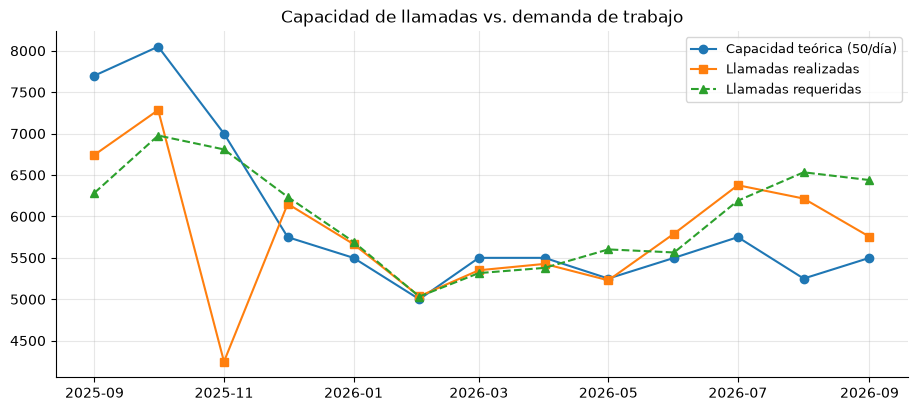

In [19]:
cap = pd.DataFrame(
    {
        "vencimientos": ren.groupby("expiry_month").size(),
        "llamadas realizadas": log.groupby("month").size(),
        "días hábiles": business_days_per_month("2025-09-01", "2026-09-30"),
        "intentos por póliza": ren.groupby("expiry_month")["Número de intentos"].mean(),
        "gestores": ren.groupby("expiry_month")["active_agents"].first(),
    }
).dropna()
cap["capacidad teórica"] = cap["gestores"] * DAILY_CALL_TARGET * cap["días hábiles"]
cap["llamadas requeridas"] = cap["vencimientos"] * cap["intentos por póliza"]
cap["utilización requerida"] = cap["llamadas requeridas"] / cap["capacidad teórica"]
display(
    cap.style.format(
        {
            "utilización requerida": "{:.0%}",
            "llamadas requeridas": "{:,.0f}",
            "intentos por póliza": "{:.2f}",
        },
        precision=0,
    )
)

c5 = cap[cap["gestores"] == 5]
deficit = c5["llamadas requeridas"].mean() / c5["capacidad teórica"].mean() - 1
print(
    f"Con 5 gestores: capacidad teórica media {c5['capacidad teórica'].mean():,.0f} llamadas/mes, requeridas {c5['llamadas requeridas'].mean():,.0f} "
    f"({deficit:+.0%}; rango mensual {c5['utilización requerida'].min() - 1:+.0%} a {c5['utilización requerida'].max() - 1:+.0%}); "
    f"realizadas {c5['llamadas realizadas'].mean():,.0f} = {c5['llamadas realizadas'].sum() / c5['llamadas requeridas'].sum():.0%} de lo requerido."
)
print(
    f"Intentos por póliza: {ren.loc[~PERIODO_5, 'Número de intentos'].mean():.2f} con 7 gestores, {ren.loc[PERIODO_5, 'Número de intentos'].mean():.2f} con 5."
)

fig, ax = plt.subplots()
ax.plot(cap.index.to_timestamp(), cap["capacidad teórica"], marker="o", label="Capacidad teórica (50/día)")
ax.plot(cap.index.to_timestamp(), cap["llamadas realizadas"], marker="s", label="Llamadas realizadas")
ax.plot(
    cap.index.to_timestamp(), cap["llamadas requeridas"], marker="^", ls="--", label="Llamadas requeridas"
)
ax.set_title("Capacidad de llamadas vs. demanda de trabajo")
ax.legend()
plt.show()

Con 5 gestores la carga del proceso actual (~2,000 vencimientos × 3.0 intentos ≈ 5,800 llamadas al mes) supera en **~6 %** la capacidad nominal de 5 × 50 llamadas por día hábil (~5,450); los gestores la cubren con ~52 llamadas al día. Mide la carga tal como se trabaja hoy, no una demanda independiente. Es un déficit real pero pequeño: no explica que la anticipación pase de 16 a 3 días. Contratar no es la primera salida; las pólizas que no necesitan llamada liberan más capacidad que la que falta.

## 8. Impacto económico

In [20]:
ref = ren[ren["lead_bucket"].isin(["8-14", "15-20"])]
tasa_ref = ref["renewed"].mean()
tarde = ren["lead_bucket"].isin(["Después del venc.", "0-3"])
meses = ren["expiry_month"].nunique()

# Estimación simple: todas las pólizas tardías renovarían a la tasa de referencia
gap = tasa_ref - ren.loc[tarde].groupby("lead_bucket", observed=True)["renewed"].mean()
com_tarde = ren.loc[tarde].groupby("lead_bucket", observed=True)["potential_commission"].sum()
perdida_simple = (gap * com_tarde).sum()

# ¿Cuánto de eso se imputa a pólizas que renuevan igual aunque se las llame tarde?
sin_efecto = ren["Forma de pago"].ne("Manual") | ren["Segmento"].eq("Flota corporativa")
perdida_sin_efecto = (
    gap * ren.loc[tarde & sin_efecto].groupby("lead_bucket", observed=True)["potential_commission"].sum()
).sum()
tasa_sin_efecto_tarde = ren.loc[tarde & sin_efecto, "renewed"].mean()


# Estimación estratificada: cada póliza tardía se compara con la tasa de referencia de su forma de pago y segmento
def perdida_estratificada(sub):
    total = 0.0
    for (pago, seg), g_ in sub.groupby(["Forma de pago", "Segmento"], observed=True):
        tasa_g = ref.loc[(ref["Forma de pago"] == pago) & (ref["Segmento"] == seg), "renewed"].mean()
        total += max(0.0, tasa_g - g_["renewed"].mean()) * g_["potential_commission"].sum()
    return total


perdida_strat = perdida_estratificada(ren[tarde])
perdida_strat_5 = perdida_estratificada(ren[tarde & PERIODO_5])
meses_5 = ren.loc[PERIODO_5, "expiry_month"].nunique()

display(
    Markdown(f"""
| Métrica | Valor |
|---|---|
| Comisión potencial total ({meses} meses) | USD {ren["potential_commission"].sum():,.0f} |
| Comisión realmente cobrada | USD {ren["earned_commission"].sum():,.0f} ({ren["earned_commission"].sum() / ren["potential_commission"].sum():.1%}) |
| Tasa de renovación con contacto a 8–20 días | {tasa_ref:.1%} |
| Tasa de renovación con contacto a ≤ 3 días o después | {ren.loc[tarde, "renewed"].mean():.1%} |
| Pólizas contactadas tarde | {tarde.sum():,} ({tarde.mean():.1%}) |
| Estimación simple de comisión perdida por contacto tardío | USD {perdida_simple:,.0f} (~USD {perdida_simple / meses:,.0f} al mes) |
| … de la cual se imputa a domiciliadas, financiadas y flotas, que renovaron al {tasa_sin_efecto_tarde:.0%} aun llamadas tarde | USD {perdida_sin_efecto:,.0f} |
| **Estimación estratificada por forma de pago × segmento** | **USD {perdida_strat:,.0f}** (~USD {perdida_strat / meses:,.0f} al mes; solo periodo de 5 gestores: ~USD {perdida_strat_5 / meses_5:,.0f} al mes) |
""")
)


| Métrica | Valor |
|---|---|
| Comisión potencial total (13 meses) | USD 4,563,284 |
| Comisión realmente cobrada | USD 2,852,946 (62.5%) |
| Tasa de renovación con contacto a 8–20 días | 71.6% |
| Tasa de renovación con contacto a ≤ 3 días o después | 41.2% |
| Pólizas contactadas tarde | 11,585 (46.0%) |
| Estimación simple de comisión perdida por contacto tardío | USD 636,321 (~USD 48,948 al mes) |
| … de la cual se imputa a domiciliadas, financiadas y flotas, que renovaron al 92% aun llamadas tarde | USD 280,612 |
| **Estimación estratificada por forma de pago × segmento** | **USD 478,195** (~USD 36,784 al mes; solo periodo de 5 gestores: ~USD 45,045 al mes) |


Es un orden de magnitud. La estimación estratificada queda 25 % por debajo de la simple porque no atribuye pérdida a pólizas que renuevan solas. Puede haber sesgo de selección, así que se valida con un piloto. Referencia: la caída bruta de 62 % a 51 % equivale a ~USD 39 k al mes.

## 9. Hallazgos

1. **El problema empezó en dic-2025** con la salida de G06 y G07: la anticipación mediana bajó de 16 a 3 días y la renovación de 62.0 % a 50.6 %. Dos causas: 16 % menos caudal y un cambio en la apertura de la cola.
2. **El déficit de capacidad es pequeño** (~6 %): contratar no es la primera palanca.
3. **La ventana que renueva es 8–14 días** (75 % frente a 41 % a 3 días o menos).
4. **Nadie prioriza por valor.**
5. **Un cuarto de la cartera casi no necesita llamada** (domiciliadas, financiadas y flotas): ~930 llamadas al mes que se pueden liberar.
6. **Los teléfonos inválidos sí son palanca** (2,401 llamadas perdidas); el horario no.
7. **G03 demuestra que se puede** llegar a la ventana con 5 gestores.
8. **Costo:** USD 37–45 k al mes de comisión perdida por contacto tardío (estratificada: ~37 k en los 13 meses y ~45 k en el periodo de 5 gestores; la caída bruta de 62 % a 51 % equivale a ~39 k; a validar con piloto).

**Qué se lleva el prototipo**

1. Cola diaria ordenada por **comisión × mejora esperada**, con objetivo de primer contacto 8–14 días antes.
2. Canal automático (WhatsApp o correo) para domiciliadas, financiadas y flotas: ~1,100 llamadas al mes liberadas con los teléfonos inválidos.
3. Cada expediente se abre **14 días** antes del vencimiento.
4. Teléfonos inválidos a corrección de datos.
5. Seguimiento de *Cotización enviada* como hipótesis del piloto.
6. Piloto A/B de 2–3 meses con línea base el periodo de 5 gestores y la tasa de sep–nov 2025 como referencia alcanzable; se aleatorizan pólizas dentro de cada gestor, no gestores enteros, porque la diferencia entre gestores (G03) supera el efecto que se quiere medir.

**Datos que se pedirían:** la regla actual de apertura de la cola, vigencia de las cotizaciones, canales de contacto registrados, reparto de carteras al salir G06 y G07 y calendario de feriados.